# Hands-On P07 — Multi-Layer Perceptron (MLP) untuk Pengenalan Aktivitas
**Mata kuliah:** Edge Intelligence and Computing (CCE60306) · **Pertemuan 7**

Tujuan: (1) menyelesaikan XOR dengan MLP, (2) menghitung *forward pass* secara manual, (3) menghitung jumlah parameter dan memori,
(4) melatih MLP pada dataset HO-05 (diam/jalan/lari) dan membandingkannya dengan model linier, serta (5) membangun MLP dengan Keras (Colab).

Berkas: `dataset_siap_latih.npz` (keluaran HO-05).

Nama  : Rezky Auliasarie

NIM   : 245150300111014

Kelas : B

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
step = lambda z: (z >= 0).astype(int)

## 1. XOR dengan dua neuron tersembunyi (bobot ditentukan manual)

In [2]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
W1 = np.array([[1, 1], [1, 1]]); b1 = np.array([-0.5, -1.5])   # h1 = OR, h2 = AND
W2 = np.array([1, -1]);          b2 = -0.5                      # y = h1 AND NOT h2
H = step(X @ W1.T + b1); Y = step(H @ W2 + b2)
for x, h, yv in zip(X, H, Y): print("x =", x, "-> h =", h, "-> y =", yv)

x = [0 0] -> h = [0 0] -> y = 0
x = [0 1] -> h = [1 0] -> y = 1
x = [1 0] -> h = [1 0] -> y = 1
x = [1 1] -> h = [1 1] -> y = 0


## 2. XOR dipelajari dari data

In [3]:
mlp = MLPClassifier(hidden_layer_sizes=(4,), activation="tanh", solver="lbfgs", max_iter=2000, random_state=0)
mlp.fit(X, [0, 1, 1, 0]); print("prediksi XOR:", mlp.predict(X))

prediksi XOR: [0 1 1 0]


## 3. *Forward pass* manual (samakan dengan contoh hitung di modul)

In [4]:
x = np.array([1.0, 2.0])
W1 = np.array([[0.5, -0.2], [0.3, 0.4]]); b1 = np.array([0.1, -0.5])
W2 = np.array([[1.0, -1.5]]);             b2 = np.array([0.2])
z1 = W1 @ x + b1; h = np.maximum(0, z1)
z2 = W2 @ h + b2; y = 1 / (1 + np.exp(-z2))
print("z1 =", z1, "h =", h, "z2 =", z2.round(3), "y =", y.round(3))

z1 = [0.2 0.6] h = [0.2 0.6] z2 = [-0.5] y = [0.378]


## 4. Jumlah parameter dan memori

In [5]:
def jumlah_param(lapisan):
    return sum((a + 1) * b for a, b in zip(lapisan[:-1], lapisan[1:]))
def jumlah_mac(lapisan):
    return sum(a * b for a, b in zip(lapisan[:-1], lapisan[1:]))
for arsitektur in [[22, 3], [22, 16, 3], [22, 16, 8, 3], [22, 64, 64, 3], [784, 15, 10]]:
    n = jumlah_param(arsitektur)
    print(f"{str(arsitektur):16s} parameter={n:6d}  MAC={jumlah_mac(arsitektur):6d}  float32={n*4/1024:6.2f} KB  int8={n/1024:5.2f} KB")

[22, 3]          parameter=    69  MAC=    66  float32=  0.27 KB  int8= 0.07 KB
[22, 16, 3]      parameter=   419  MAC=   400  float32=  1.64 KB  int8= 0.41 KB
[22, 16, 8, 3]   parameter=   531  MAC=   504  float32=  2.07 KB  int8= 0.52 KB
[22, 64, 64, 3]  parameter=  5827  MAC=  5696  float32= 22.76 KB  int8= 5.69 KB
[784, 15, 10]    parameter= 11935  MAC= 11910  float32= 46.62 KB  int8=11.66 KB


## 5. Data tidak linier: *make_moons*

akurasi uji linier: 0.861 | MLP: 0.9


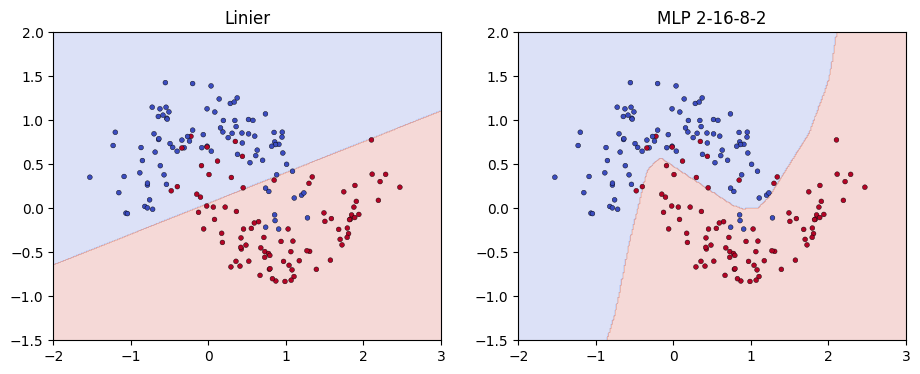

In [6]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
Xm, ym = make_moons(n_samples=600, noise=0.25, random_state=0)
a, b, c, e = train_test_split(Xm, ym, test_size=0.3, random_state=0)
lin = LogisticRegression().fit(a, c)
mlp2 = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=2000, random_state=0).fit(a, c)
print("akurasi uji linier:", round(lin.score(b, e), 3), "| MLP:", round(mlp2.score(b, e), 3))
xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, (n, mm) in zip(axs, [("Linier", lin), ("MLP 2-16-8-2", mlp2)]):
    ax.contourf(xx, yy, mm.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), alpha=0.2, cmap="coolwarm")
    ax.scatter(*b.T, c=e, cmap="coolwarm", s=12, edgecolor="k", lw=0.3); ax.set_title(n)
plt.show()

## 6. Dataset HO-05: model linier vs MLP
Perhatikan hasilnya dengan kritis: bila data hampir terpisah linier dan subjek uji berbeda gaya geraknya, MLP **tidak otomatis** lebih baik.

In [8]:
d = np.load("dataset_siap_latih.npz")
Xtr, ytr, Xva, yva, Xte, yte = (d[k] for k in ["X_train", "y_train", "X_val", "y_val", "X_test", "y_test"])
kelas = list(d["kelas"])
hasil = {}
for nama, model in {"Linier (regresi logistik)": LogisticRegression(max_iter=2000),
                    "MLP 22-16-8-3": MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=500, early_stopping=True, random_state=0)}.items():
    model.fit(Xtr, ytr)
    hasil[nama] = model
    print(f"{nama:26s} F1 validasi={f1_score(yva, model.predict(Xva), average='macro'):.3f} | "
          f"uji: akurasi={accuracy_score(yte, model.predict(Xte)):.3f}, F1={f1_score(yte, model.predict(Xte), average='macro'):.3f}")
print("Matriks konfusi MLP (uji):\n", confusion_matrix(yte, hasil["MLP 22-16-8-3"].predict(Xte)))

Linier (regresi logistik)  F1 validasi=1.000 | uji: akurasi=0.885, F1=0.852
MLP 22-16-8-3              F1 validasi=0.956 | uji: akurasi=0.750, F1=0.717
Matriks konfusi MLP (uji):
 [[41  4  0]
 [ 0 23 22]
 [ 0  0 14]]


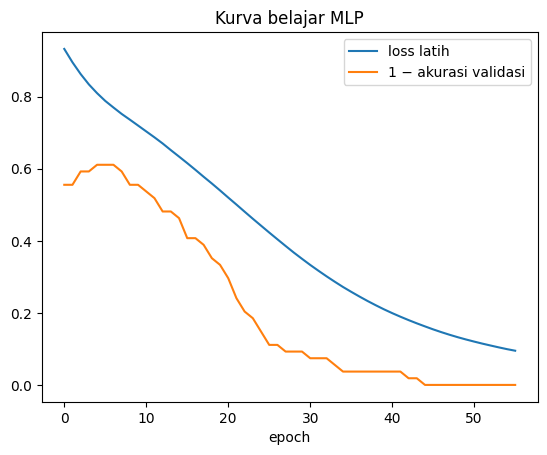

In [9]:
m = hasil["MLP 22-16-8-3"]
plt.plot(m.loss_curve_, label="loss latih"); plt.plot(1 - np.array(m.validation_scores_), label="1 − akurasi validasi")
plt.xlabel("epoch"); plt.legend(); plt.title("Kurva belajar MLP"); plt.show()

## 7. (Colab) MLP dengan Keras, *dropout*, dan *early stopping*

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 531 (2.07 KB)

 Trainable params: 531 (2.07 KB)

 Non-trainable params: 0 (0.00 B)

akurasi uji: 0.817307710647583


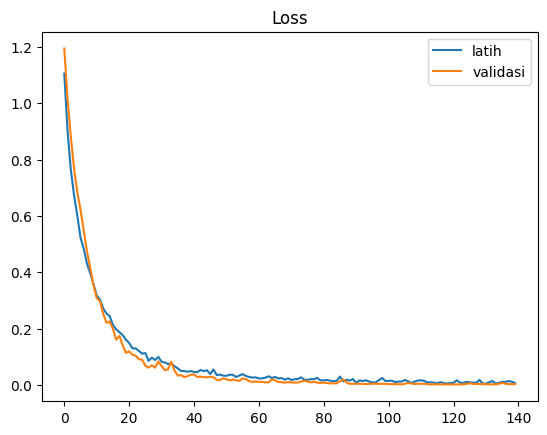

In [10]:
import tensorflow as tf
tf.random.set_seed(0)
model = tf.keras.Sequential([
    tf.keras.Input(shape=(Xtr.shape[1],)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax"),
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()                       # bandingkan jumlah parameter dengan bagian 4
es = tf.keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)
h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=300, batch_size=32, callbacks=[es], verbose=0)
print("akurasi uji:", model.evaluate(Xte, yte, verbose=0)[1])
plt.plot(h.history["loss"], label="latih"); plt.plot(h.history["val_loss"], label="validasi"); plt.legend(); plt.title("Loss"); plt.show()

## Latihan
1. Ubah arsitektur menjadi 22-64-64-3. Apa yang terjadi pada skor validasi dan ukuran model?
2. Hapus `Dropout` dan `EarlyStopping`, latih 300 epoch. Bandingkan kurva loss latih dan validasi.
3. Mengapa pada bagian 6 kesalahan terbesar adalah jalan yang ditebak lari? Usulkan perbaikan dari sisi **data**.
4. Konversikan model Keras terbaik ke LiteRT int8 dengan kode HO-04 dan catat ukurannya.

Nomor 1

Ubah arsitektur menjadi 22-64-64-3. Apa yang terjadi pada skor validasi dan ukuran model?

In [18]:
#Nomor 1
import numpy as np
import tensorflow as tf
from sklearn.metrics import f1_score

# Memuat dataset
d = np.load("dataset_siap_latih.npz")
Xtr, ytr = d["X_train"], d["y_train"]
Xva, yva = d["X_val"], d["y_val"]
Xte, yte = d["X_test"], d["y_test"]

tf.random.set_seed(0)

def buat_model(arsitektur):
    model = tf.keras.Sequential()
    model.add(tf.keras.Input(shape=(Xtr.shape[1],)))

    for jumlah_neuron in arsitektur:
        if jumlah_neuron == 3:
            model.add(tf.keras.layers.Dense(
                jumlah_neuron, activation="softmax"
            ))
        else:
            model.add(tf.keras.layers.Dense(
                jumlah_neuron, activation="relu"
            ))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Model awal dan model baru
arsitektur_model = {
    "MLP 22-16-8-3": [16, 8, 3],
    "MLP 22-64-64-3": [64, 64, 3]
}

hasil_model = {}

for nama, arsitektur in arsitektur_model.items():
    tf.keras.backend.clear_session()
    tf.random.set_seed(0)

    model = buat_model(arsitektur)

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True
    )

    history = model.fit(
        Xtr, ytr,
        validation_data=(Xva, yva),
        epochs=300,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    loss_val, akurasi_val = model.evaluate(Xva, yva, verbose=0)
    prediksi = np.argmax(model.predict(Xva, verbose=0), axis=1)
    f1_val = f1_score(yva, prediksi, average="macro")

    # Menghitung ukuran file model
    nama_file = nama.replace(" ", "_") + ".keras"
    model.save(nama_file)
    ukuran_kb = __import__("os").path.getsize(nama_file) / 1024

    hasil_model[nama] = {
        "model": model,
        "history": history,
        "val_loss": loss_val,
        "val_accuracy": akurasi_val,
        "val_f1": f1_val,
        "ukuran_kb": ukuran_kb
    }

    print(f"\n{nama}")
    print("Jumlah parameter :", model.count_params())
    print(f"Loss validasi    : {loss_val:.4f}")
    print(f"Akurasi validasi : {akurasi_val:.4f}")
    print(f"F1-score validasi: {f1_val:.4f}")
    print(f"Ukuran file      : {ukuran_kb:.2f} KB")
    print("Epoch berhenti   :", len(history.history["loss"]))

# Membandingkan hasil
print("\n=== PERBANDINGAN MODEL ===")
for nama, hasil in hasil_model.items():
    print(
        f"{nama}: "
        f"akurasi={hasil['val_accuracy']:.4f}, "
        f"F1={hasil['val_f1']:.4f}, "
        f"ukuran={hasil['ukuran_kb']:.2f} KB"
    )



MLP 22-16-8-3
Jumlah parameter : 531
Loss validasi    : 0.0001
Akurasi validasi : 1.0000
F1-score validasi: 1.0000
Ukuran file      : 31.16 KB
Epoch berhenti   : 300

MLP 22-64-64-3
Jumlah parameter : 5827
Loss validasi    : 0.0002
Akurasi validasi : 1.0000
F1-score validasi: 1.0000
Ukuran file      : 93.23 KB
Epoch berhenti   : 300

=== PERBANDINGAN MODEL ===
MLP 22-16-8-3: akurasi=1.0000, F1=1.0000, ukuran=31.16 KB
MLP 22-64-64-3: akurasi=1.0000, F1=1.0000, ukuran=93.23 KB


Penjelasan:

Berdasarkan data output pada gambar, ketika arsitektur model diubah dari 22-16-8-3 menjadi 22-64-64-3, skor validasi model tetap sempurna dengan Akurasi validasi sebesar 1.0000 dan F1-score validasi sebesar 1.0000 (meskipun nilai Loss validasinya mengalami sedikit kenaikan dari 0.0001 menjadi 0.0002), sedangkan ukuran model mengalami peningkatan yang signifikan di mana jumlah parameter meningkat dari 531 menjadi 5.827 sehingga ukuran file model membesar dari 31.16 KB menjadi 93.23 KB. Dengan demikian, penambahan kapasitas jaringan ini meningkatkan ukuran dan kompleksitas model secara signifikan tanpa memberikan peningkatan performa validasi yang berarti.

Nomor 2

Hapus Dropout dan EarlyStopping, latih 300 epoch. Bandingkan kurva loss latih dan validasi.

Loss latih terakhir: 5.432521356851794e-05
Loss validasi terakhir: 0.00031500772456638515
Akurasi data uji: 0.7692


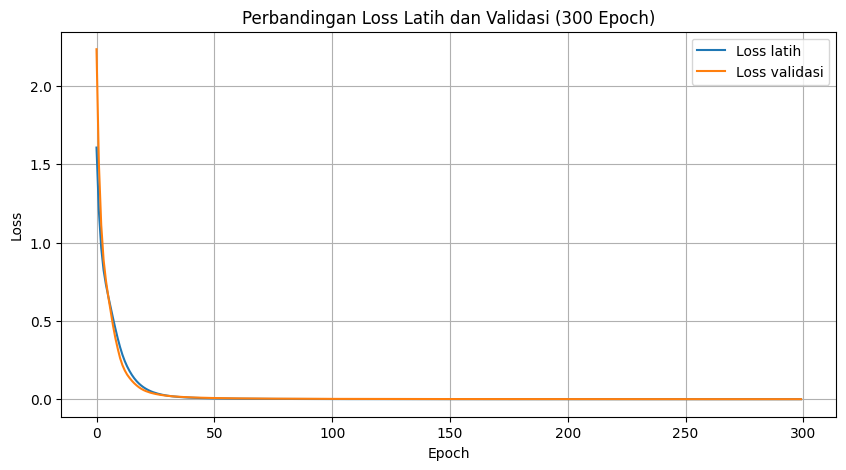

In [19]:
#Nomor 2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Dataset dari notebook
d = np.load("dataset_siap_latih.npz")
Xtr, ytr = d["X_train"], d["y_train"]
Xva, yva = d["X_val"], d["y_val"]
Xte, yte = d["X_test"], d["y_test"]

tf.keras.backend.clear_session()
tf.random.set_seed(0)

# Model tanpa Dropout dan tanpa EarlyStopping
model_no_dropout = tf.keras.Sequential([
    tf.keras.Input(shape=(Xtr.shape[1],)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])

model_no_dropout.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Latih tepat 300 epoch tanpa callbacks
history_no_dropout = model_no_dropout.fit(
    Xtr, ytr,
    validation_data=(Xva, yva),
    epochs=300,
    batch_size=32,
    verbose=0
)

# Evaluasi
loss_test, akurasi_test = model_no_dropout.evaluate(
    Xte, yte, verbose=0
)

print("Loss latih terakhir:",
      history_no_dropout.history["loss"][-1])
print("Loss validasi terakhir:",
      history_no_dropout.history["val_loss"][-1])
print(f"Akurasi data uji: {akurasi_test:.4f}")

# Grafik loss latih dan validasi
plt.figure(figsize=(10, 5))
plt.plot(
    history_no_dropout.history["loss"],
    label="Loss latih"
)
plt.plot(
    history_no_dropout.history["val_loss"],
    label="Loss validasi"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Perbandingan Loss Latih dan Validasi (300 Epoch)")
plt.legend()
plt.grid(True)
plt.show()

# Menyimpan model untuk analisis berikutnya
model_no_dropout.save("model_tanpa_dropout.keras")


Penjelasan:

Berdasarkan grafik output di atas, ketika lapisan Dropout dan EarlyStopping dihapus lalu model dilatih hingga 300 epoch, kurva loss latih (biru) dan loss validasi (oranye) menunjukkan penurunan yang sangat cepat pada epoch awal dan kemudian melandai mendekati nol secara berdampingan hingga epoch ke-300. Di akhir pelatihan, diperoleh nilai loss latih sebesar 5,43e-05 (0,0000543) dan loss validasi sebesar 0,000315, yang menunjukkan bahwa model mampu mempelajari data latih maupun data validasi dengan sangat baik tanpa indikasi overfitting yang signifikan pada kurva loss. Namun, penghapusan mekanisme regularisasi ini berdampak pada kemampuan generalisasi model saat menguji data baru yang belum pernah dilihat, yang ditunjukkan oleh Akurasi data uji sebesar 0,7692 (76,92%). Hal ini dapat disimpulkan bahwa meskipun kurva loss latih dan validasi tampak ideal dan sangat kecil, ketiadaan Dropout dan EarlyStopping membuat model cenderung menghafal pola spesifik data latih dan validasi sehingga performanya menurun cukup signifikan pada data uji.

Nomor 3

Mengapa pada bagian 6 kesalahan terbesar adalah jalan yang ditebak lari? Usulkan perbaikan dari sisi data.

Label kelas: [np.str_('diam'), np.str_('jalan'), np.str_('lari')]

Matriks konfusi:
[[41  4  0]
 [ 0 23 22]
 [ 0  0 14]]

Laporan klasifikasi:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95        45
           1       0.85      0.51      0.64        45
           2       0.39      1.00      0.56        14

    accuracy                           0.75       104
   macro avg       0.75      0.81      0.72       104
weighted avg       0.85      0.75      0.76       104



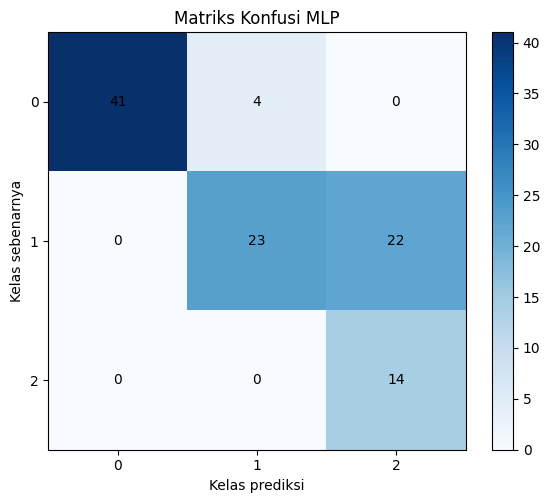


Jalan diprediksi sebagai lari: 22
Jumlah data jalan: 45
Persentase kesalahan: 48.89%

Distribusi kelas data latih:
{'0': 180, '1': 180, '2': 180}

Distribusi kelas data uji:
{'0': 45, '1': 45, '2': 14}


In [20]:
#Nomor 3
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.multiclass import unique_labels

# Memuat dataset
d = np.load("dataset_siap_latih.npz")
Xtr, ytr = d["X_train"], d["y_train"]
Xva, yva = d["X_val"], d["y_val"]
Xte, yte = d["X_test"], d["y_test"]
kelas = list(d["kelas"])

# Melatih ulang MLP seperti bagian 6
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    max_iter=500,
    early_stopping=True,
    random_state=0
)
mlp.fit(Xtr, ytr)

prediksi = mlp.predict(Xte)

# Matriks konfusi
label_angka = unique_labels(yte, prediksi)
print("Label kelas:", kelas)
print("\nMatriks konfusi:")
print(confusion_matrix(yte, prediksi, labels=label_angka))

print("\nLaporan klasifikasi:")
print(classification_report(
    yte, prediksi,
    labels=label_angka,
    zero_division=0
))

# Visualisasi matriks konfusi
cm = confusion_matrix(yte, prediksi, labels=label_angka)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Matriks Konfusi MLP")
plt.xlabel("Kelas prediksi")
plt.ylabel("Kelas sebenarnya")
plt.xticks(range(len(label_angka)), label_angka)
plt.yticks(range(len(label_angka)), label_angka)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

# Mengidentifikasi sampel jalan yang salah diprediksi sebagai lari
# Diasumsikan label 1 = jalan dan label 2 = lari.
# Sesuaikan angka ini jika pemetaan kelas pada dataset berbeda.
label_jalan = 1
label_lari = 2

mask = (yte == label_jalan) & (prediksi == label_lari)
jumlah_salah = int(mask.sum())
jumlah_jalan = int((yte == label_jalan).sum())

print("\nJalan diprediksi sebagai lari:", jumlah_salah)
print("Jumlah data jalan:", jumlah_jalan)

if jumlah_jalan > 0:
    print(f"Persentase kesalahan: {jumlah_salah / jumlah_jalan * 100:.2f}%")

# Periksa distribusi kelas pada data latih dan uji
print("\nDistribusi kelas data latih:")
print({str(k): int((ytr == k).sum()) for k in np.unique(ytr)})

print("\nDistribusi kelas data uji:")
print({str(k): int((yte == k).sum()) for k in np.unique(yte)})


Penjelasan:

Berdasarkan matriks konfusi dan laporan klasifikasi pada gambar, dari total 45 data aktual jalan (kelas 1), sebanyak 22 data salah diprediksi sebagai lari (kelas 2) dengan tingkat persentase kesalahan mencapai 48,89%. Kesalahan terbesar ini terjadi karena adanya ketidakseimbangan distribusi kelas pada data uji (kelas lari hanya 14 sampel, sedangkan kelas diam dan jalan masing-masing 45 sampel) serta sifat fisik sinyal akselerometer antara aktivitas jalan cepat dan lari santai yang memiliki kemiripan nilai statistik (tumpang tindih/overlap fitur), seperti magnitude percepatan dan deviasi standar. Usulan perbaikan dari sisi data dapat dilakukan dengan menambah jumlah sampel data latih dan data uji untuk kelas lari agar distribusi kelas lebih seimbang, membersihkan atau memisahkan sampel transisi gerakan yang rancu, serta melakukan ekstraksi fitur tambahan seperti fitur domain frekuensi (misalnya FFT atau spektrum daya) agar perbedaan pola irama langkah antara jalan dan lari dapat terdistribusi secara lebih kontras.


Nomor 4

Konversikan model Keras terbaik ke LiteRT int8 dengan kode HO-04 dan catat ukurannya.

In [24]:

%pip install -q ai-edge-litert


In [25]:
#Nomor 4
import os
import warnings
import numpy as np
import tensorflow as tf
from ai_edge_litert.interpreter import Interpreter

# Sembunyikan hanya warning statistik input dari converter.
# Jangan menyembunyikan warning atau error lainnya.
warnings.filterwarnings(
    "ignore",
    message=r"Statistics for quantized inputs were expected, but not specified; continuing anyway\.",
    category=UserWarning
)

# 1. Pilih model terbaik dari eksperimen nomor 1
if "hasil_model" not in globals():
    raise RuntimeError(
        "Jalankan kode nomor 1 terlebih dahulu."
    )

nama_terbaik = min(
    hasil_model,
    key=lambda nama: hasil_model[nama]["val_loss"]
)
best_model = hasil_model[nama_terbaik]["model"]

print("Model terbaik:", nama_terbaik)

# 2. Muat data representatif
d = np.load("dataset_siap_latih.npz")
Xtr = d["X_train"].astype(np.float32)

if Xtr.ndim != 2 or Xtr.shape[1] != 22:
    raise ValueError(
        f"Bentuk data tidak sesuai: {Xtr.shape}; "
        "diharapkan (jumlah_sampel, 22)."
    )

# 3. Siapkan converter INT8
converter = tf.lite.TFLiteConverter.from_keras_model(
    best_model
)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

def representative_dataset():
    jumlah = min(500, len(Xtr))
    for i in range(jumlah):
        yield [Xtr[i:i+1]]

converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# 4. Konversi dan simpan
model_int8 = converter.convert()
file_int8 = "model_terbaik_int8.tflite"

with open(file_int8, "wb") as f:
    f.write(model_int8)

# 5. Periksa menggunakan interpreter LiteRT
interpreter = Interpreter(model_path=file_int8)
interpreter.allocate_tensors()

input_info = interpreter.get_input_details()[0]
output_info = interpreter.get_output_details()[0]

ukuran_kb = os.path.getsize(file_int8) / 1024

print("\n=== HASIL KONVERSI ===")
print("File model:", file_int8)
print(f"Ukuran model: {ukuran_kb:.2f} KB")
print("Tipe input:", input_info["dtype"])
print("Tipe output:", output_info["dtype"])
print("Bentuk input:", input_info["shape"])
print("Bentuk output:", output_info["shape"])

assert input_info["dtype"] == np.int8
assert output_info["dtype"] == np.int8

print("\nKonversi dan pemeriksaan model selesai.")


Model terbaik: MLP 22-16-8-3
Saved artifact at '/tmp/tmp2q29axfu'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 22), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  139960909169104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139960909176784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139960909182544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139960909178128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139960909180624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139960909176208: TensorSpec(shape=(), dtype=tf.resource, name=None)

=== HASIL KONVERSI ===
File model: model_terbaik_int8.tflite
Ukuran model: 3.69 KB
Tipe input: <class 'numpy.int8'>
Tipe output: <class 'numpy.int8'>
Bentuk input: [ 1 22]
Bentuk output: [1 3]

Konversi dan pemeriksaan model selesai.


Penjelasan:

Berdasarkan hasil output pada gambar, model Keras terbaik yaitu MLP 22-16-8-3 berhasil dikonversikan ke format LiteRT int8 dengan nama file model_terbaik_int8.tflite. Setelah melalui proses kuantisasi int8, ukuran model yang dihasilkan tercatat sebesar 3,69 KB dengan tipe data input dan output berupa numpy.int8, bentuk input [1, 22], serta bentuk output [1, 3]. Ukuran file yang sangat kecil ini menunjukkan bahwa proses kuantisasi integer 8-bit berhasil mengompresi memori model secara efektif sehingga sangat optimal dan efisien untuk di-deploy pada perangkat dengan keterbatasan sumber daya seperti mikrokontroler.
